# Static Shapley attribution on GA4 ecommerce journeys

Cooperative-game Shapley-value attribution on the same GA4 journey extract
used across all examples. The coalition game is the default cumulative one:
*v(S) = conversions on journeys whose unique channel set is contained in S*.
The Shapley values are exact and deterministic — no sampling — and they
allocate every observed conversion.

In [1]:
# In Colab, install the package first:
# %pip install "do-attribution[viz,temporal]"
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Sum of Shapley values")
warnings.filterwarnings("ignore", message="Total removal effect is 0")
pd.set_option("display.width", 160)

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## Load and summarize the GA4 journeys

In [2]:
journeys = pd.read_csv("ga4_attribution_journeys.csv")

required = {"path", "conversion", "anchor_timestamp"}
assert required.issubset(journeys.columns), f"missing columns: {required - set(journeys.columns)}"
assert journeys["path"].notna().all() and (journeys["path"].str.len() > 0).all()
assert journeys["conversion"].isin([0, 1]).all()

paths = journeys["path"]
conversions = journeys["conversion"]
timestamps = pd.to_datetime(journeys["anchor_timestamp"]).dt.tz_localize(None)

channels = sorted({channel for path in paths for channel in path.split(" > ")})
path_lengths = paths.str.count(" > ") + 1
print(f"journeys        : {len(journeys):,}")
print(f"conversions     : {conversions.sum():,}  (rate {conversions.mean():.4f})")
print(f"date range      : {timestamps.min().date()} to {timestamps.max().date()}")
print(f"channels ({len(channels)})    : {', '.join(channels)}")
print(f"path length     : mean {path_lengths.mean():.2f}, max {path_lengths.max()}; "
      f"{(path_lengths > 1).mean():.1%} of journeys are multi-touch")
journeys.head()

journeys        : 272,792
conversions     : 4,848  (rate 0.0178)
date range      : 2020-11-01 to 2021-01-31
channels (8)    : Affiliate, Direct, Email, Organic Search, Organic Social, Other, Paid Search, Referral
path length     : mean 1.17, max 12; 11.4% of journeys are multi-touch


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12T04:11:17Z,2020-12-12T04:11:17Z,1,1,0
1,journey_0000002,Direct,0,2021-01-07T18:35:34Z,2021-01-07T18:35:34Z,1,1,0
2,journey_0000003,Direct,0,2021-01-20T11:04:59Z,2021-01-20T11:04:59Z,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04T09:21:11Z,2020-11-04T13:43:30Z,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11T17:25:12Z,2020-12-11T17:25:12Z,1,1,0


## Fit the Shapley model

In [3]:
from do_attribution import ShapleyAttribution

shapley = ShapleyAttribution()
shapley_result = shapley.fit(paths, conversions)
print(f"characteristic function: {shapley_result['characteristic_function']}")
print(f"normalization status   : {shapley_result['normalization_status']}")
if shapley_result["attribution"] is None:
    print(f"normalized shares are unavailable ({shapley_result['normalization_reason']}); "
          "the raw Shapley values below are not shares")
else:
    shares = pd.Series(shapley_result["attribution"], name="share").sort_values(ascending=False)
    display(shares.round(4).to_frame())
    print(f"shares sum to {shares.sum():.6f}")

characteristic function: cumulative
normalization status   : available


,share
Referral,0.4307
Organic Search,0.3854
Direct,0.0986
Other,0.0668
Paid Search,0.0133
Email,0.0040
Organic Social,0.0009
Affiliate,0.0003


shares sum to 1.000000


## Raw Shapley values

Raw values are on the game's own scale: conversions. Under the cumulative
game each converting journey splits its conversion equally among the
distinct channels it touched, so the raw values are non-negative and sum to
the total number of observed conversions. The shares above are these values
divided by that total.

In [4]:
raw = pd.Series(shapley_result["shapley_values"], name="raw_shapley_value")
display(raw.sort_values(ascending=False).round(2).to_frame())
print(f"raw values sum to {raw.sum():,.2f}; observed conversions: {conversions.sum():,}")

,raw_shapley_value
Referral,2087.92
Organic Search,1868.33
Direct,478.17
Other,324.00
Paid Search,64.50
Email,19.25
Organic Social,4.50
Affiliate,1.33


raw values sum to 4,848.00; observed conversions: 4,848


## Coalition results

In [5]:
value_function = shapley_result["value_function"]
print(f"observed coalitions: {len(value_function)} of {2 ** len(channels)} possible")
top_coalitions = sorted(value_function.items(), key=lambda kv: -kv[1])[:10]
display(pd.DataFrame(
    [{"coalition": " + ".join(coalition), "size": len(coalition), "conversions": value}
     for coalition, value in top_coalitions]
))

observed coalitions: 89 of 256 possible


,coalition,size,conversions
0,Referral,1,1384
1,Organic Search,1,1294
2,Organic Search + Referral,2,669
3,Direct + Referral,2,294
4,Direct + Organic Search + Referral,3,184
5,Direct,1,149
6,Other + Referral,2,134
7,Direct + Organic Search,2,122
8,Other,1,114
9,Organic Search + Other + Referral,3,114


## Model summary (plain-text report)

In [6]:
print(shapley.summary())

Attribution Summary
Model: ShapleyAttribution
Epoch source: static
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Data
+-----------+--------+-------------+---------+------------------------------------------------------+
| Cohort    | Paths  | Conversions | Conv. % | Top channels                                         |
+-----------+--------+-------------+---------+------------------------------------------------------+
| All paths | 272792 | 4848        | 1.78%   | Referral 43.07%, Organic Search 38.54%, Direct 9.86% |
+-----------+--------+-------------+---------+------------------------------------------------------+

Raw Shapley values (signed)
+----------------+------------+
| Channel        | Value      |
+----------------+------------+
| Referral       | +2087.9167 |
| Organic Search | +1868.3333 |
| Direct         | +478.1667  |
| Other          | +324.0000  |
| Paid Search    | +64.5000   |
| Email          | +19.2500   |
| Organic Social | +4.5000    |
| Aff

## Plots

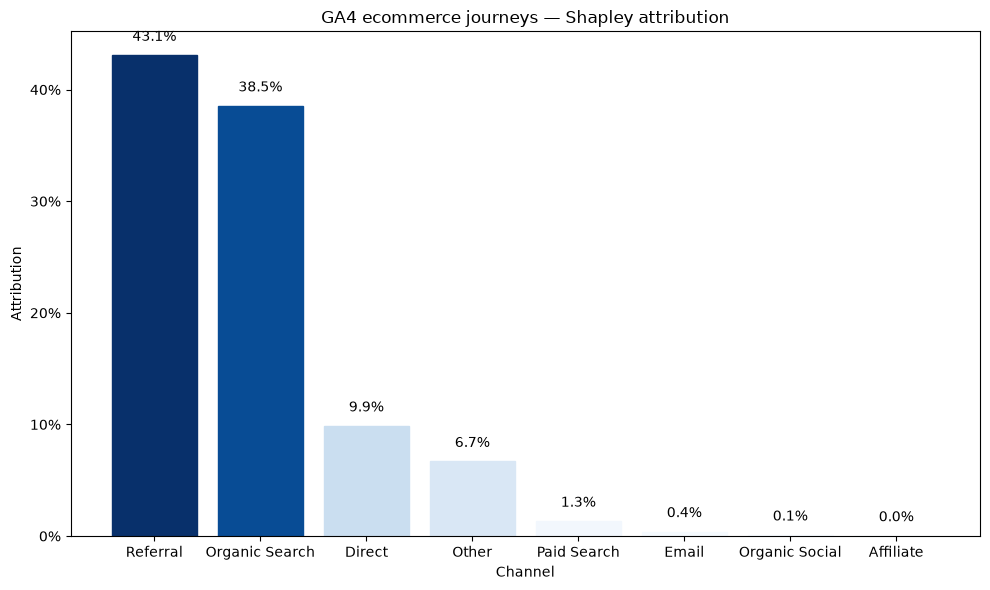

In [7]:
from do_attribution.visualization import plot_attribution

fig = plot_attribution(shapley_result["attribution"],
                       title="GA4 ecommerce journeys — Shapley attribution")
fig.savefig(IMAGES / "ga4_shapley_attribution.png", dpi=110, bbox_inches="tight")
plt.show()

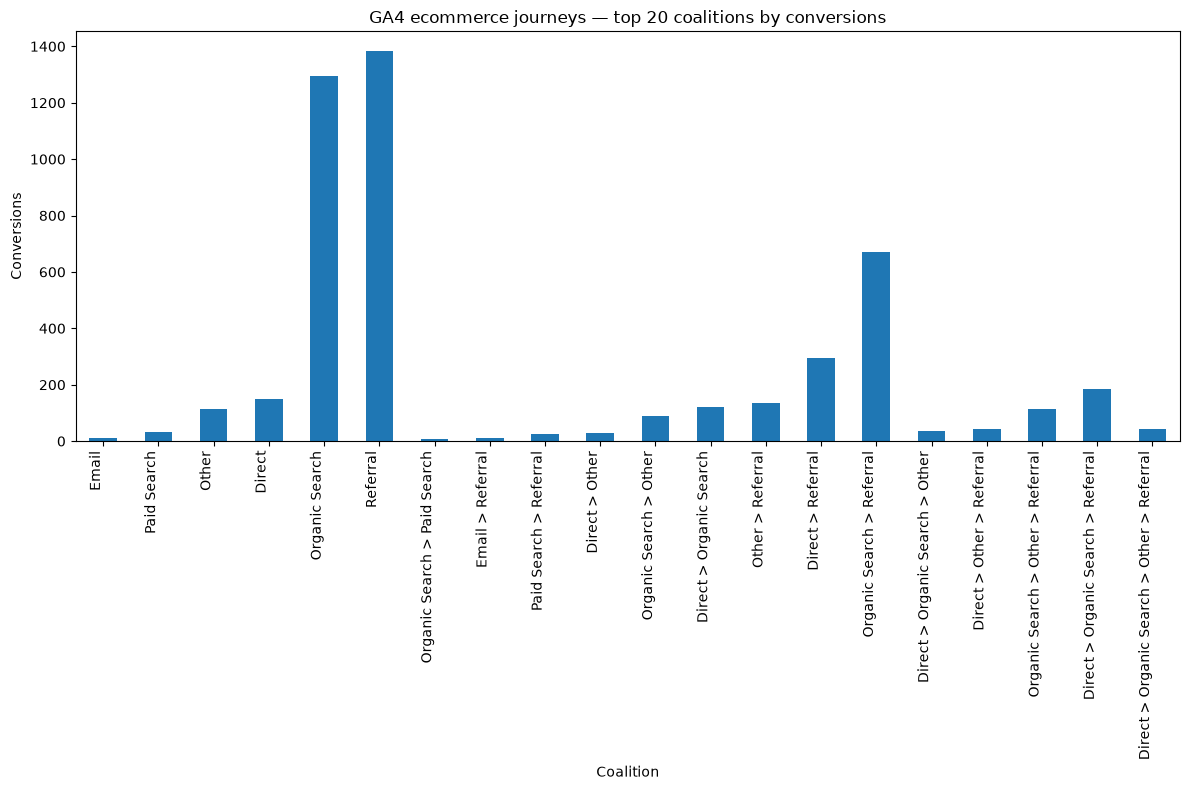

In [8]:
from do_attribution.visualization import plot_coalition_values

top_20 = dict(sorted(value_function.items(), key=lambda kv: -kv[1])[:20])
fig = plot_coalition_values(top_20,
                            title="GA4 ecommerce journeys — top 20 coalitions by conversions")
fig.savefig(IMAGES / "ga4_coalition_values.png", dpi=110, bbox_inches="tight")
plt.show()